In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sionna.rt import (
    load_scene,
    Transmitter,
    Receiver,
    PlanarArray,
    PathSolver,
    RadioMapSolver,
    Camera
)

In [2]:
scene = load_scene("test_scene/test_scene.xml")

In [3]:
for i, obj in enumerate(scene.objects.values()):

    print(f"{obj.name}: {obj.radio_material.name}")

    if i >= 10:
        break

elm__7: itu_concrete
elm__4: itu_marble
elm__5: itu_metal


In [4]:

# ============================================================
# TRANSMITTER ARRAY
# ============================================================

scene.tx_array = PlanarArray(
    num_rows=4,
    num_cols=4,
    vertical_spacing=0.5,
    horizontal_spacing=0.5,
    pattern="tr38901",
    polarization="V"
)


# ============================================================
# RECEIVER ARRAY
# ============================================================

scene.rx_array = PlanarArray(
    num_rows=1,
    num_cols=1,
    vertical_spacing=0.5,
    horizontal_spacing=0.5,
    pattern="iso",
    polarization="V"
)


# ============================================================
# TRANSMITTER
# ============================================================

tx = Transmitter(
    name="tx",
    position=[-107, 43, 10],
    orientation=[0.0, 0.0, 0.0]
)

scene.add(tx)


# ============================================================
# RECEIVER
# ============================================================

rx = Receiver(
    name="rx",
    position=[160, -74, 2],
    orientation=[0.0, 0.0, 0.0]
)

scene.add(rx)

In [5]:
scene.frequency = 3.5e9

In [6]:

rm_solver = RadioMapSolver()

In [7]:
rm = rm_solver(
    scene,
    max_depth=5,
    samples_per_tx=1_000_000,
    cell_size=(2.0, 2.0),
    center=[0, 0, 1.5],
    size=[400, 400],
    orientation=[0, 0, 0]
)


print()
print("Radio map computed!")
print("Path gain shape:")
print(rm.path_gain.shape)



Radio map computed!
Path gain shape:
(1, 200, 200)


In [8]:

# ============================================================
# PREVIEW RADIO MAP
# ============================================================

scene.preview(
    radio_map=rm,
    rm_metric="path_gain",
    rm_db_scale=True
)


In [9]:
# ============================================================
# RAY TRACING
# ============================================================

path_solver = PathSolver()

paths = path_solver(
    scene,
    max_depth=5,
    los=True,
    specular_reflection=True,
    diffuse_reflection=False,
    refraction=False,
    diffraction=False
)


print()
print("Ray tracing completed.")



Ray tracing completed.


In [10]:
# ============================================================
# CONVERT PATHS TO CIR
# ============================================================

a, tau = paths.cir(
    normalize_delays=False
)


print()
print("CIR computed.")

print("Coefficient shape:")
print(a[0].shape)

print("Delay shape:")
print(tau.shape)


# ===========


CIR computed.
Coefficient shape:
(1, 1, 1, 16, 10, 1)
Delay shape:
(1, 1, 10)


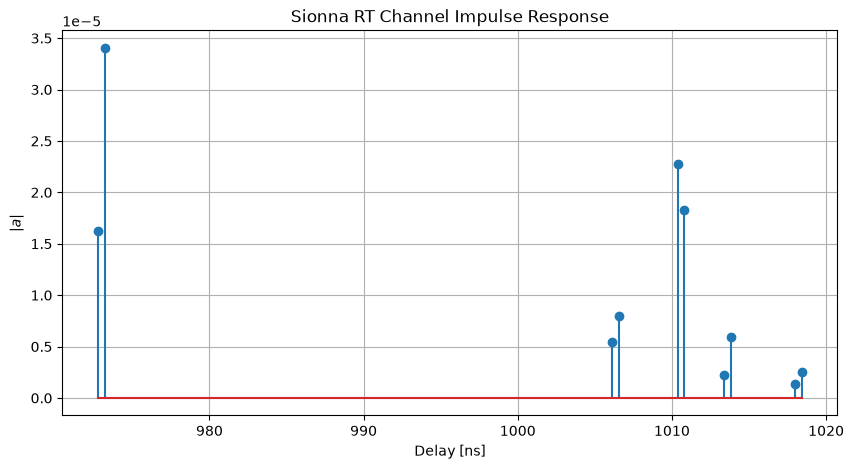

In [11]:
# ============================================================
# PLOT CIR
# ============================================================

a_np = a[0].numpy()
tau_np = tau.numpy()

plt.figure(figsize=(10, 5))

plt.stem(
    tau_np[0, 0, :] * 1e9,
    np.abs(a_np[0, 0, 0, 0, :, 0])
)

plt.xlabel("Delay [ns]")
plt.ylabel(r"$|a|$")
plt.title("Sionna RT Channel Impulse Response")

plt.grid(True)

plt.show()

In [12]:
# ============================================================
# PREVIEW RAY PATHS
# ============================================================

scene.preview(
    paths=paths,
    radio_map=rm,
    rm_metric="path_gain",
    rm_db_scale=True
)

In [13]:
# ============================================================
# OPTIONAL: SAVE RENDER
# ============================================================

camera = Camera(
    position=[330, -190, 80],
    look_at=[0, 0, 5]
)

scene.render_to_file(
    camera=camera,
    filename="sionna_rt_result.png",
    paths=paths,
    radio_map=rm,
    rm_metric="path_gain",
    rm_db_scale=True,
    resolution=[1600, 1000],
    num_samples=128,
    show_devices=True,
    show_orientations=False
)

print()
print("==========================================")
print("SIMULATION COMPLETE")
print("==========================================")

print("Output:")
print("sionna_rt_result.png")


SIMULATION COMPLETE
Output:
sionna_rt_result.png
